In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import MaxNLP
from pathlib import Path
import json
from tqdm.auto import tqdm

tqdm.pandas(desc="Applying")
%load_ext autoreload
%autoreload 2
    
from datetime import date
date_str = date.today().isoformat()

In [2]:
# Load the translated text sample (25 per country --> 250 samples)
df_t=pd.read_json("2026-05-02 new translated.json")

df=pd.read_json("clean_df.json")
#df["text"] = df.apply(MaxNLP.make_one_text,detailed=False, axis=1)

In [3]:
df.loc[2:,"QID8"].str.len().describe()

count    4220.000000
mean      117.288389
std       148.364699
min        10.000000
25%        69.000000
50%        86.000000
75%       121.000000
max      3416.000000
Name: QID8, dtype: float64

In [4]:
import re
import numpy as np
causes_labels=df.loc[0,df.columns.str.startswith("QID9")]
causes_labels=causes_labels.str.split("- ").str[-1]
causes_labels=causes_labels.str.split("(").str[0]
causes=df.loc[2:,df.columns.str.startswith("QID9")]
causes = causes.map(
    lambda x: int(m.group()) if (m := re.search(r'\d', str(x))) else np.nan
)
causes.columns=causes_labels
causes.head(2)

,EU political actors,National political actors,Russia's war on Ukraine,Over-reliance on renewable energy,Over-reliance on fossil fuels,Media actors,Large dependency on energy imports from only a few suppliers,"To confirm that you read carefully, please select now """,Uncontrollable natural disasters,Other external factors
6,3.0,3.0,4.0,2.0,4.0,4.0,4.0,2,2.0,4.0
8,2.0,2.0,1.0,3.0,4.0,3.0,5.0,2,3.0,1.0


In [5]:
# cause map

#cause_map={cause: [] for cause in causes.columns}
#x_mode.columns
cause_map={'EU political actors ': ['EU political actors','EU sanctions against Russia','Insufficient EU coordination and communication'],
 'National political actors ': ['National political actors','Insufficient political efforts to make energy affordable'],
 "Russia's war on Ukraine": ["Russia's war on Ukraine"],
 'Over-reliance on renewable energy': ['Too-fast energy transition','Reduced nuclear or fossil energy production capacity'],
 'Over-reliance on fossil fuels': ['Dependence on fossil fuels',],
 'Media actors ': ['Media actors'],
 'Large dependency on energy imports from only a few suppliers': ['Energy import dependence vulnerability'],
 'Uncontrollable natural disasters ': ['Uncontrollable natural disasters'],
 'Other external factors ': ['Abstract societal and ideological explanations','External shocks and technical failures','Industry and market actors']}

In [6]:
questions=df_t[["QID5","QID8","QID10","QID15","QID19"]].iloc[0,:]
df_t[["QID5","QID8","QID10","QID15","QID19"]]

#df_t.loc["questions",["QID5","QID8","QID10","QID15","QID19"]]=questions
#df_t[["QID5","QID8","QID10","QID15","QID19"]].to_json("2026-04-29 Kaira Causes of the energy crisis.json")

,QID5,QID8,QID10,QID15,QID19
5813,je ne saurais l'expliquer c'est un sujet trop ...,"les riches et les industrielles, ceux de tout ...",je ne saurais l'expliquer trop compliquer pour...,elle est très mal gérée car ce sont toujours l...,tout devrait être revu ce ne sont que des inco...
8998,"Cenny energii elektrycznej, to znaczy że wzros...",Izrael który bezprawnie okupuje tereny Palesty...,W zasadzie to się nikt nie zajmował bo są oni ...,Więcej osób popadło w pułapkę zielonego ładu i...,Budowa elektrowni atomowej jest konieczna i to...
6937,Augmentation du mazout et du gaz de chauffage ...,Les fluctuations des marchés des énergies qui ...,"De mon niveau, on a juste vu desaides aux prof...","On voyage moins, les trajets en voiture sont c...",Anticiper davantage les plans b en cas de soud...
1343,oorlog oekraine hebben de prijzen de hoogte in...,Is eigelijk niets nieuws temeer dat nooit op t...,Eigelijk plijven ze het zelfde doen en komen z...,Ze hebben bewezen dat ze niet bekwaam zijn en ...,Nieuwe centrales bouwen desnoods met andere la...
7283,Pour moi il y a eu la crise énergétique lorsqu...,C'est le debut de la guerre en Ukraine qui a f...,ça sort completement de mes compétences. Les a...,Certains matériaux qui nécessite beaucoup d'én...,Permettre des relations plus fortes entre pays...
...,...,...,...,...,...
6614,"La enorme subida de precios, que, además, no ...",Depender demasiado que energías procedentes de...,Los países deben operar por sus propios recurs...,"Menos consumo en los hogares, por la subida de...","""El hambre espabila"" dice el refrán. Por dos,..."
776,Los políticos no tienen ni idea y sólo saben r...,Los políticos corruptos y ladrones de mierda y...,"Son todos unos ladrones, mentirosos, chorizos,...","No han hecho nada por la gente, sólo para sus ...",Que los políticos corruptos no vuelven a tocar...
5455,"La comida subes , los alquileres cada vez más ...","No nos dicen la verdad , nos tienen engañados ...","La manejan muy mal ya que, ellos si pueden per...","Ya que no se puede pagar , mucha gente se tien...",Nose pero como sigan así la mayoría de español...
9423,Cuando vino el apagón y nos quedamos a oscuras...,Con la crisis de la guerra de Rusia y Ucrania ...,El gobierno Español estuvo muy eficiente con l...,Yo creo qué ha influido bastante en Europa y s...,Debería de influir mucho para las políticas de...


# Evaluation: full dataset

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import glob

codebook_name="causes"

filelist=glob.glob("2026-06-1* causes_run_*.json")
print(filelist)


x_runs=len(filelist)
files=[pd.read_json(file).drop_duplicates("orig_index").set_index("orig_index").ge(0.5).astype(int) for file in filelist]
x = pd.concat(files,
    keys=range(len(files)), names=["run"])
#filelist=[pd.read_json(f"2026-04-22 {codebook_name}_run_{i}.json").set_index("orig_index").ge(0.5).astype(int) for i in range(0)]

x_mode = x.groupby("orig_index").agg(lambda s: s.mode().iat[0]) # use the median


alphas = MaxNLP.kripp_alpha_all_variables(x, decimals=2)

alphas


['2026-06-10 causes_run_1_full.json', '2026-06-10 causes_run_0_full.json', '2026-06-11 causes_run_4_full.json', '2026-06-10 causes_run_3_full.json', '2026-06-10 causes_run_2_full.json']


,krippendorff_alpha,assessment
variable,,
Russia's war on Ukraine,0.97,reliable
Uncontrollable natural disasters,0.95,reliable
Reduced nuclear or fossil energy production capacity,0.94,reliable
EU sanctions against Russia,0.94,reliable
Industry and market actors,0.93,reliable
Energy import dependence vulnerability,0.92,reliable
External shocks and technical failures,0.91,reliable
EU political actors,0.89,reliable
National political actors,0.89,reliable


<Axes: >

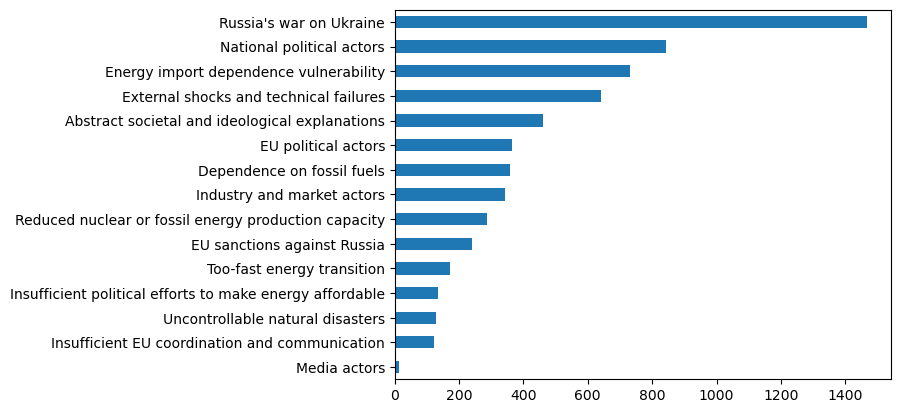

In [9]:
x_mode.sum().sort_values().plot.barh()

In [10]:
x_mode[x_mode["Media actors"].eq(1)]

,Abstract societal and ideological explanations,Dependence on fossil fuels,EU political actors,EU sanctions against Russia,Energy import dependence vulnerability,External shocks and technical failures,Industry and market actors,Insufficient EU coordination and communication,Insufficient political efforts to make energy affordable,Media actors,National political actors,Reduced nuclear or fossil energy production capacity,Russia's war on Ukraine,Too-fast energy transition,Uncontrollable natural disasters
orig_index,,,,,,,,,,,,,,,
103,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
148,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
512,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
705,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
1046,0,0,0,0,0,0,1,0,0,1,1,0,1,0,0
1084,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0
1259,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0
3044,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3564,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [11]:
import pandas as pd
import MaxStat
from scipy.stats import mannwhitneyu
import numpy as np


likert_rank = MaxStat.pairwise_mwu_ranking(causes, alpha=0.05, alternative="two-sided")


rows = []
for cause, cols in cause_map.items():
    code   = x_mode[cols].max(axis=1)          # any of the mapped codes = 1
    lik    = causes[cause]                     # Likert scores for this cause
    u, p, r = MaxStat.mwu_effect(lik[code == 1], lik[code == 0])

    rows.append({
        "cause"            : cause,
        "mapped_codes"     : ", ".join(cols),
        "Closed‑Q [mean]"  : lik.mean().round(2),
        "Open‑Q [n]"       : code.sum(),
        "rosenthal_c"      : r.round(2),
        "p_value (MWU)"    : p,
        "rank"             : likert_rank.get(cause, np.nan),
    })

comparison_df = (pd.DataFrame(rows)
                   .set_index("cause")
                   .sort_values("rank")
                   .assign(rank=lambda df: df["rank"].astype(int))
                )
pd.set_option("display.max_colwidth", None)
display(comparison_df)

,mapped_codes,Closed‑Q [mean],Open‑Q [n],rosenthal_c,p_value (MWU),rank
cause,,,,,,
Russia's war on Ukraine,Russia's war on Ukraine,4.13,1468,0.32,7.921257e-152,1
Other external factors,"Abstract societal and ideological explanations, External shocks and technical failures, Industry and market actors",3.58,1346,0.04,2.315614e-12,2
Large dependency on energy imports from only a few suppliers,Energy import dependence vulnerability,4.17,732,0.16,1.539014e-47,3
Over-reliance on fossil fuels,Dependence on fossil fuels,3.76,359,0.15,2.824509e-36,4
EU political actors,"EU political actors, EU sanctions against Russia, Insufficient EU coordination and communication",4.09,630,0.07,1.576468e-17,5
National political actors,"National political actors, Insufficient political efforts to make energy affordable",4.09,894,0.14,6.151908e-46,5
Uncontrollable natural disasters,Uncontrollable natural disasters,2.86,128,0.12,1.514819e-22,6
Media actors,Media actors,3.34,12,0.04,1.177285e-04,7
Over-reliance on renewable energy,"Too-fast energy transition, Reduced nuclear or fossil energy production capacity",3.13,409,0.08,6.954683e-18,8


In [12]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import textwrap

#%pip install python-louvain  ## IMPORTANT -- module name is not community

#import community as community_louvain   # python-louvain

import community.community_louvain as community_louvain

co = x_mode.T @ x_mode
freq = x_mode.sum(axis=0)

sim = co / np.sqrt(np.outer(freq, freq))

G = nx.from_pandas_adjacency(sim)

# prune weak edges ---> Influences the clusters!
G.remove_edges_from(
    [(u, v) for u, v, w in G.edges(data="weight") if w < 0.05] # 0.01 connects the media actors
)

G.remove_edges_from(
    [(u, v) for u, v, w in G.edges(data="weight") if w > 0.999]
)


partition = community_louvain.best_partition(G, weight="weight")


clusters = pd.Series(partition).sort_values()
print(clusters)


print(f"Number of communities: {len(partition)}")

community_sizes = sorted(
    [len(c) for c in partition],
    reverse=True
)

partition

Abstract societal and ideological explanations              0
Reduced nuclear or fossil energy production capacity        0
Too-fast energy transition                                  0
Dependence on fossil fuels                                  1
EU sanctions against Russia                                 1
Energy import dependence vulnerability                      1
External shocks and technical failures                      1
Russia's war on Ukraine                                     1
Uncontrollable natural disasters                            1
EU political actors                                         2
Insufficient EU coordination and communication              2
Industry and market actors                                  3
Insufficient political efforts to make energy affordable    3
National political actors                                   3
Media actors                                                4
dtype: int64
Number of communities: 15


{'Abstract societal and ideological explanations': 0,
 'Dependence on fossil fuels': 1,
 'EU political actors': 2,
 'EU sanctions against Russia': 1,
 'Energy import dependence vulnerability': 1,
 'External shocks and technical failures': 1,
 'Industry and market actors': 3,
 'Insufficient EU coordination and communication': 2,
 'Insufficient political efforts to make energy affordable': 3,
 'Media actors': 4,
 'National political actors': 3,
 'Reduced nuclear or fossil energy production capacity': 0,
 "Russia's war on Ukraine": 1,
 'Too-fast energy transition': 0,
 'Uncontrollable natural disasters': 1}

In [13]:

degree_cent = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(
    G,
    normalized=True
)
closeness = nx.closeness_centrality(G)
eigenvector = nx.eigenvector_centrality(
    G,
    max_iter=5000
)
pagerank = nx.pagerank(G)


centrality_df = pd.DataFrame({
    "Community": pd.Series(partition),
    "Degree": degree_cent,
    "Betweenness": betweenness,
    "Closeness": closeness,
    "Eigenvector": eigenvector,
    "PageRank": pagerank
})

community_sizes = (
    pd.Series(partition)
    .value_counts()
    .to_dict()
)


centrality_df.index.name = "Node"

centrality_df.sort_values("Betweenness")


,Community,Degree,Betweenness,Closeness,Eigenvector,PageRank
Node,,,,,,
EU sanctions against Russia,1,0.285714,0.000000,0.548701,1.471238e-01,0.046576
Insufficient EU coordination and communication,2,0.285714,0.000000,0.548701,1.513050e-01,0.037928
Insufficient political efforts to make energy affordable,3,0.214286,0.000000,0.524845,1.086464e-01,0.035380
Media actors,4,0.000000,0.000000,0.000000,3.065314e-09,0.010601
Uncontrollable natural disasters,1,0.428571,0.000000,0.603571,2.152239e-01,0.046443
Too-fast energy transition,0,0.500000,0.001570,0.635338,2.498073e-01,0.056850
Abstract societal and ideological explanations,0,0.500000,0.003401,0.635338,2.424015e-01,0.047218
Dependence on fossil fuels,1,0.500000,0.003768,0.635338,2.409433e-01,0.069813
External shocks and technical failures,1,0.714286,0.020539,0.754464,3.216859e-01,0.082622


In [14]:
import networkx as nx
import pandas as pd

summary = {
    "Nodes": G.number_of_nodes(),
    "Edges": G.number_of_edges(),
    "Density": nx.density(G),
    "Connected Components": nx.number_connected_components(G),
    "Average Clustering Coefficient": nx.average_clustering(G),
    "Transitivity": nx.transitivity(G),
}

# Largest connected component
largest_cc = max(nx.connected_components(G), key=len)
Gcc = G.subgraph(largest_cc)

summary["Largest Component Size"] = len(largest_cc)
summary["Average Path Length (LCC)"] = nx.average_shortest_path_length(Gcc)
summary["Diameter (LCC)"] = nx.diameter(Gcc)

summary_df = pd.DataFrame(summary, index=["Value"]).T
print(summary_df)

                                    Value
Nodes                           15.000000
Edges                           56.000000
Density                          0.533333
Connected Components             2.000000
Average Clustering Coefficient   0.763178
Transitivity                     0.712088
Largest Component Size          14.000000
Average Path Length (LCC)        1.384615
Diameter (LCC)                   2.000000


In [15]:
partition = community_louvain.best_partition(G, weight="weight")
node_sizes = [freq[node] * 20 for node in G.nodes()]
node_colors = [partition[node] for node in G.nodes()]

# edge labels = raw counts
edge_labels = {
    (u, v): int(co.loc[u, v]) for u, v in G.edges()
}

# raw co-occurrence per edge
edge_weights = [co.loc[u, v] for u, v in G.edges()]

# optional: normalize for visibility
max_w = max(edge_weights)

edge_widths = [10 * (w / max_w) for w in edge_weights]  # scale factor = 3


def wrap_label(label, width=20):
    return "\n".join(textwrap.wrap(str(label), width))

labels = {n: wrap_label(n, 17) for n in G.nodes()}

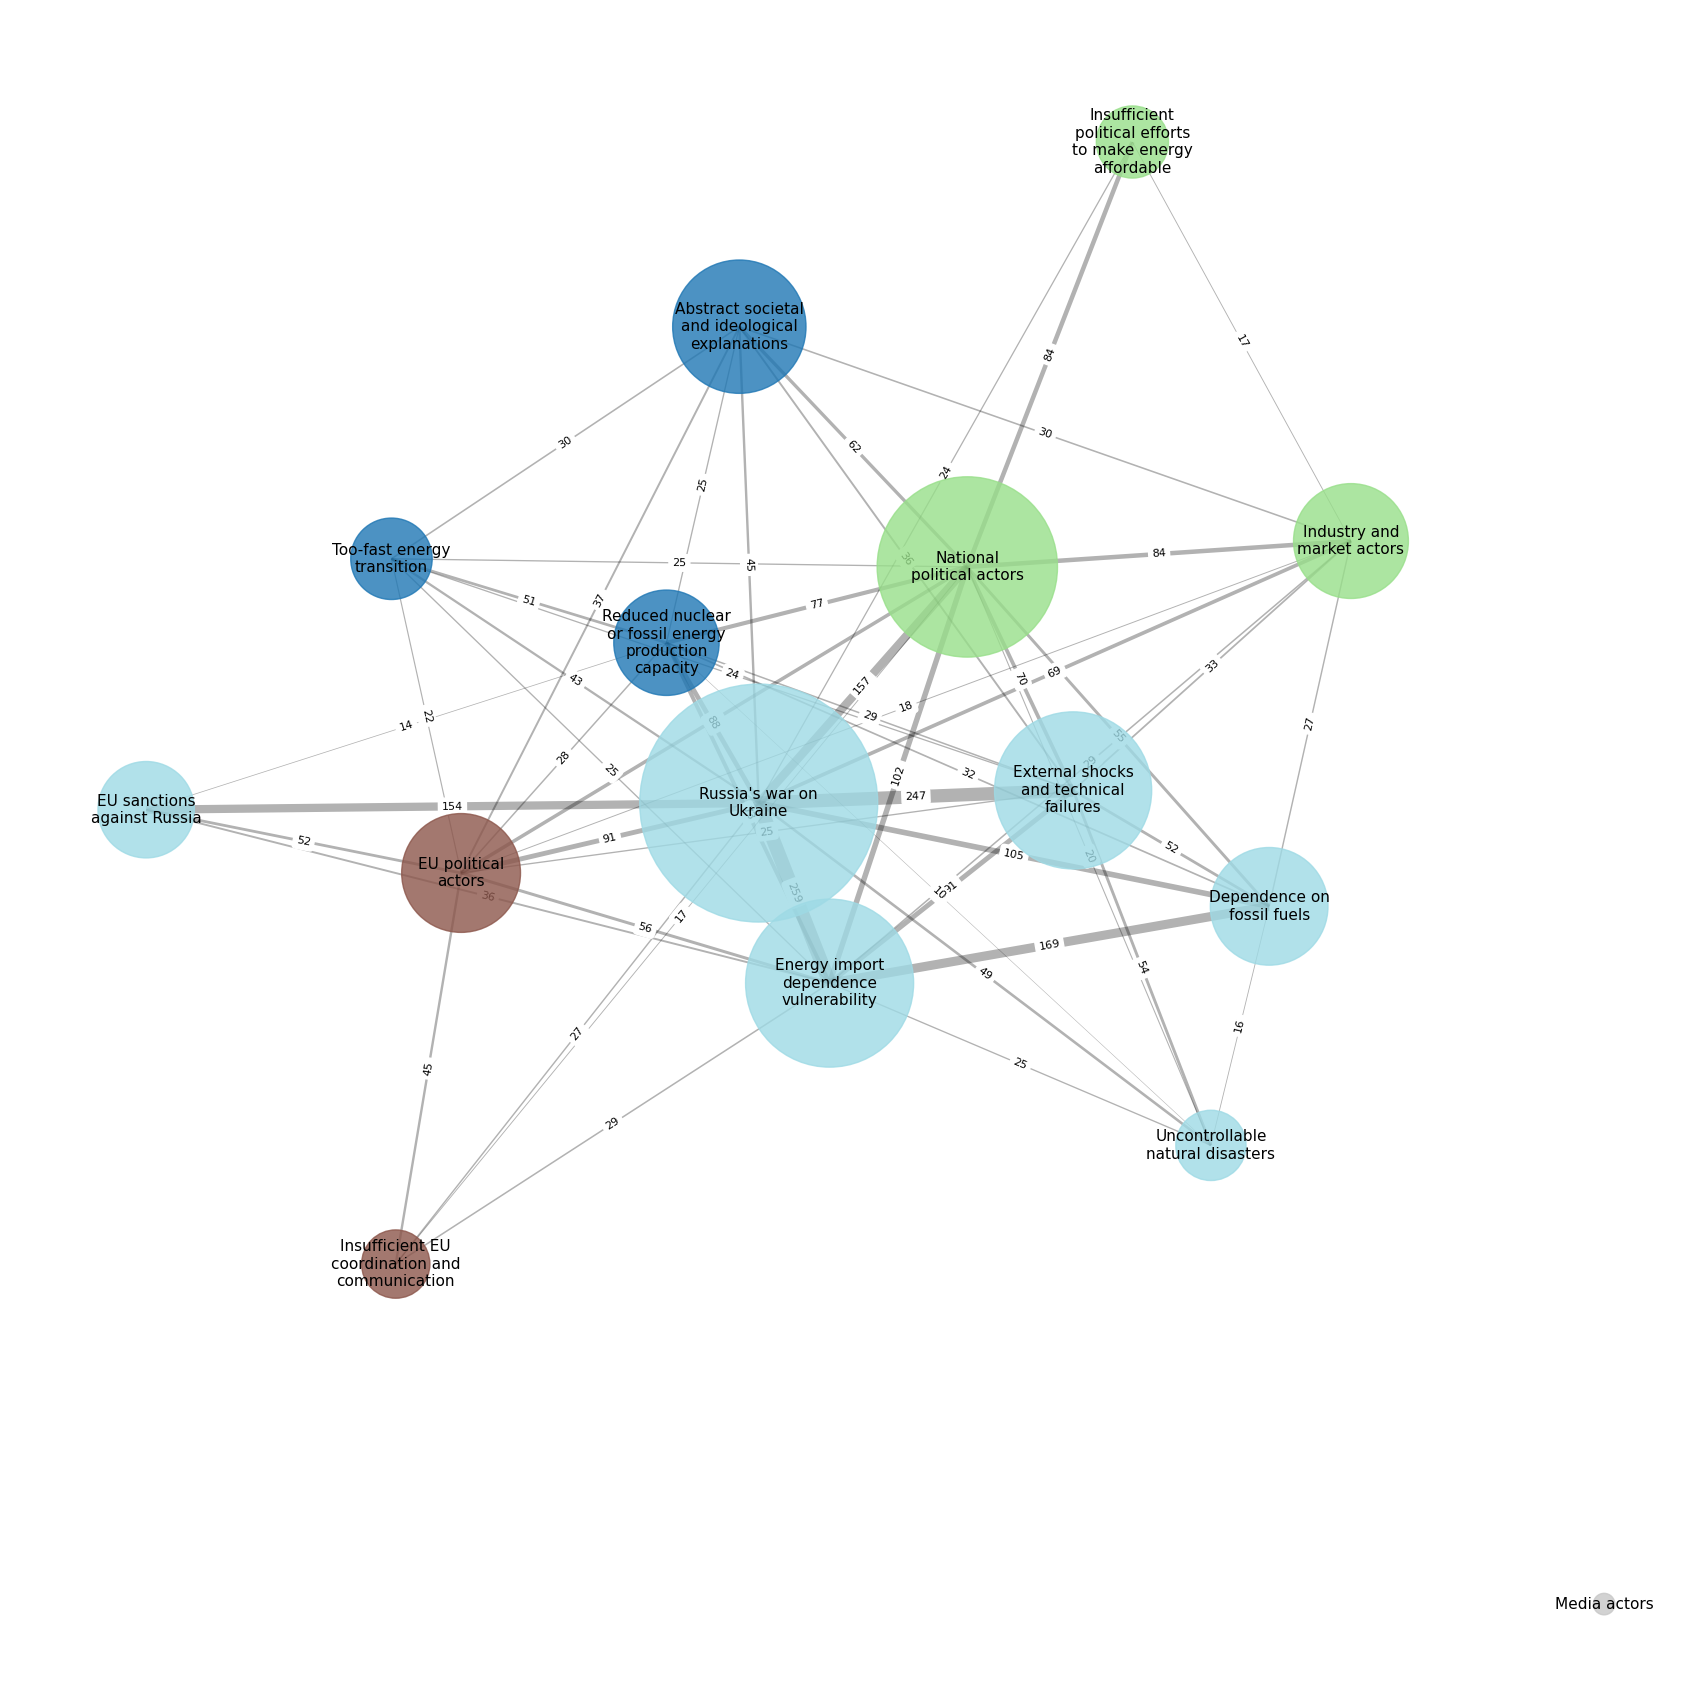

In [16]:
# plotting

pos = nx.spring_layout(
    G,
    seed=42,
    k=2,
    iterations=200,
    weight="weight"
)

plt.figure(figsize=(17, 17))

nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    edgecolors=None,
    alpha=0.8
)


nx.draw_networkx_edges(
    G, pos,
    width=edge_widths,
    alpha=0.3
)


nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=8
)

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=11
)

plt.axis("off")
plt.tight_layout()
plt.savefig("label_network_clusters.pdf", bbox_inches="tight")
plt.show()

In [17]:
df_cpi=x_mode.join(df[["country","politics_num","income_num"]])

In [18]:
df_cpi=df_cpi[df_cpi["country"]!="Others"]

In [19]:
df_cpi.iloc[2:,:-2]

,Abstract societal and ideological explanations,Dependence on fossil fuels,EU political actors,EU sanctions against Russia,Energy import dependence vulnerability,External shocks and technical failures,Industry and market actors,Insufficient EU coordination and communication,Insufficient political efforts to make energy affordable,Media actors,National political actors,Reduced nuclear or fossil energy production capacity,Russia's war on Ukraine,Too-fast energy transition,Uncontrollable natural disasters,country
orig_index,,,,,,,,,,,,,,,,
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Germany
8,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,Italy
9,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,Italy
11,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,Germany
14,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,Italy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11146,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,Germany
11151,1,1,1,0,1,0,0,1,0,0,0,0,1,0,0,Belgium
11152,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,Belgium


In [20]:
df_cpi.iloc[2:,:-1]

,Abstract societal and ideological explanations,Dependence on fossil fuels,EU political actors,EU sanctions against Russia,Energy import dependence vulnerability,External shocks and technical failures,Industry and market actors,Insufficient EU coordination and communication,Insufficient political efforts to make energy affordable,Media actors,National political actors,Reduced nuclear or fossil energy production capacity,Russia's war on Ukraine,Too-fast energy transition,Uncontrollable natural disasters,country,politics_num
orig_index,,,,,,,,,,,,,,,,,
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Germany,3.0
8,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,Italy,None
9,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,Italy,4.0
11,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,Germany,5.0
14,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,Italy,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11146,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,Germany,2.0
11151,1,1,1,0,1,0,0,1,0,0,0,0,1,0,0,Belgium,2.0
11152,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,Belgium,2.0


In [21]:
import MaxStat

results = MaxStat.topic_country_association(
    df            = df_cpi.iloc[2:,:-1],
    topic_col     = list(x_mode.columns),   # or simply `x_mode.columns`
    country_col   = "country",
    resid_thr     = 1.96,                  # default = 95 % residual threshold
    n_resamples   = 20_000,                # Monte‑Carlo resamples (default)
    alpha         = 0.05
)
results

,test,χ²,p_raw,p_formatted,CramérsV,over_countries [φ],under_countries [φ],p_adj,significant
code,,,,,,,,,
Abstract societal and ideological explanations,χ² (MC),16.42,0.112544,.11,0.06,,,0.120583,False
Dependence on fossil fuels,χ² (MC),52.18,0.000050,< .001,0.11,,,0.000125,True
EU political actors,χ² (MC),91.19,0.000050,< .001,0.15,Czech Republic (0.11),,0.000125,True
EU sanctions against Russia,χ² (MC),29.69,0.008200,.01,0.08,,,0.013666,True
Energy import dependence vulnerability,χ² (MC),98.42,0.000050,< .001,0.15,Germany (0.10),,0.000125,True
External shocks and technical failures,χ² (MC),38.31,0.000100,< .001,0.10,,,0.000214,True
Industry and market actors,χ² (MC),18.49,0.082046,.08,0.07,,,0.094668,False
Insufficient EU coordination and communication,χ² (MC),13.37,0.171691,.17,0.06,,,0.171691,False
Insufficient political efforts to make energy affordable,χ² (MC),33.53,0.030848,.03,0.09,,,0.046273,True


In [22]:

df_c=x_mode.iloc[2:].join(df["country"][2:])
df_c=df_c[df_c.country!="Other"]


country_col = "country"
code_cols = [c for c in df_c.columns if c != country_col]


In [23]:

assoc_with_ci = MaxStat.country_code_association(df_c, country_col="country", code_cols=code_cols)

assoc_with_ci[assoc_with_ci["significant"]]#.to_clipboard()

,country,code,a,b,c,d,phi,odds,p_raw,phi_ci_low,phi_ci_high,or_ci_low,or_ci_high,p_adj,significant
14,Poland,Dependence on fossil fuels,62,367,297,3498,0.071775,1.989706,1.439820e-05,0.041688,0.101862,1.482824,2.669859,1.542664e-04,True
16,Czech Republic,Dependence on fossil fuels,1,124,358,3741,-0.048212,0.084272,2.634047e-04,-0.078341,-0.018083,0.011742,0.604792,2.079511e-03,True
18,Spain,Dependence on fossil fuels,27,534,332,3331,-0.051730,0.507293,4.484419e-04,-0.081855,-0.021606,0.339121,0.758864,3.057558e-03,True
20,Germany,EU political actors,54,882,312,2976,-0.054917,0.583987,2.780902e-04,-0.085036,-0.024798,0.433282,0.787112,2.085676e-03,True
24,Poland,EU political actors,68,361,298,3497,0.085885,2.210452,2.728890e-07,0.055831,0.115938,1.662590,2.938846,5.847622e-06,True
26,Czech Republic,EU political actors,32,93,334,3765,0.105126,3.878694,9.440365e-09,0.075128,0.135123,2.556189,5.885429,3.011491e-07,True
30,Germany,EU sanctions against Russia,79,857,162,3126,0.062905,1.778772,8.472403e-05,0.032801,0.093010,1.345208,2.352074,7.942877e-04,True
40,Germany,Energy import dependence vulnerability,229,707,502,2786,0.100983,1.797602,2.174822e-10,0.070972,0.130993,1.506375,2.145131,1.631117e-08,True
43,France,Energy import dependence vulnerability,108,660,623,2833,-0.040416,0.744112,8.342739e-03,-0.070556,-0.010276,0.596472,0.928296,4.057390e-02,True
47,Romania,Energy import dependence vulnerability,19,198,712,3295,-0.052597,0.444083,3.067422e-04,-0.082719,-0.022474,0.275439,0.715982,2.191016e-03,True


In [24]:
# -------------------------------------------------
#  Cell 5 – Pivot matrices (the exact input for the heat‑map)
# -------------------------------------------------
phi_mat, odds_mat, sig_mat = MaxStat.pivot_matrices(assoc_with_ci)
phi_mat

code,Abstract societal and ideological explanations,Dependence on fossil fuels,EU political actors,EU sanctions against Russia,Energy import dependence vulnerability,External shocks and technical failures,Industry and market actors,Insufficient EU coordination and communication,Insufficient political efforts to make energy affordable,Media actors,National political actors,Reduced nuclear or fossil energy production capacity,Russia's war on Ukraine,Too-fast energy transition,Uncontrollable natural disasters
country,,,,,,,,,,,,,,,
Belgium,-0.000103,0.021343,-0.002307,0.000538,0.036511,0.043286,0.006301,0.019049,-0.007035,-0.010452,-0.022299,0.016752,0.009975,0.023168,-0.019972
Czech Republic,-0.020799,-0.048212,0.105126,-0.006817,-0.028186,-0.003660,0.009624,0.037012,0.007982,-0.009321,0.024768,-0.008440,-0.004231,0.006433,-0.022721
France,-0.007516,-0.031415,0.009719,-0.028628,-0.040416,0.014785,0.001841,0.007359,0.074869,-0.013629,-0.018577,0.003985,0.000117,-0.028798,0.034831
Germany,-0.038671,0.033623,-0.054917,0.062905,0.100983,-0.050585,-0.035073,-0.002777,-0.045094,-0.007059,0.074796,0.070518,0.089426,0.002556,-0.044439
Italy,-0.005974,0.014952,-0.012985,0.026080,0.020196,0.052958,0.024097,0.013953,-0.006006,-0.023319,-0.067764,-0.069533,0.021299,-0.070420,0.005590
Netherlands,0.024298,0.000261,-0.024270,0.013875,0.032992,-0.009001,-0.000334,-0.006803,-0.016951,0.049015,-0.035527,-0.001666,0.012939,0.024238,-0.015177
Poland,0.015532,0.071775,0.085885,-0.018505,-0.000502,0.013115,-0.039460,-0.029548,-0.034357,0.026229,-0.016706,0.048972,0.006429,0.077450,0.009144
Portugal,0.030477,-0.005795,-0.006851,-0.023713,-0.006623,0.018855,0.001630,0.006843,-0.004467,-0.010028,-0.054551,-0.050818,-0.033001,-0.012302,-0.002768
Romania,0.004530,-0.028622,-0.006872,-0.029502,-0.052597,-0.041511,0.001692,-0.001390,0.006491,0.007728,0.015419,0.013634,-0.012197,0.006315,0.027678


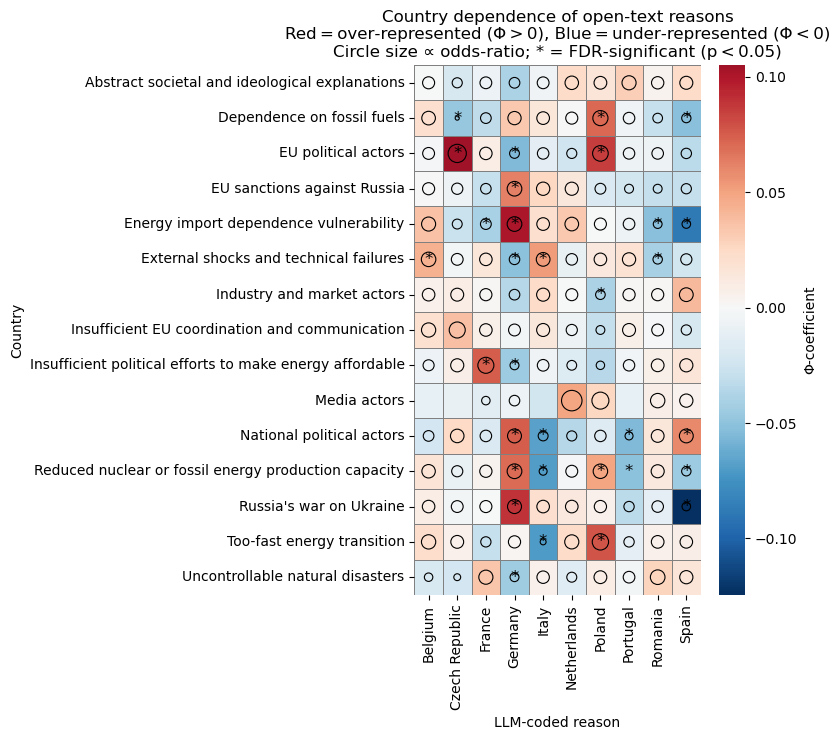

In [25]:
# -------------------------------------------------
#  Cell 6 – Plot the heat‑map (set make_plot=False to skip)
# -------------------------------------------------
make_plot = True
if make_plot:
    ax = MaxStat.plot_heatmap(phi_mat.T, odds_mat.T, sig_mat.T,
                         circle_scale=250, cmap="RdBu_r")
    plt.show()

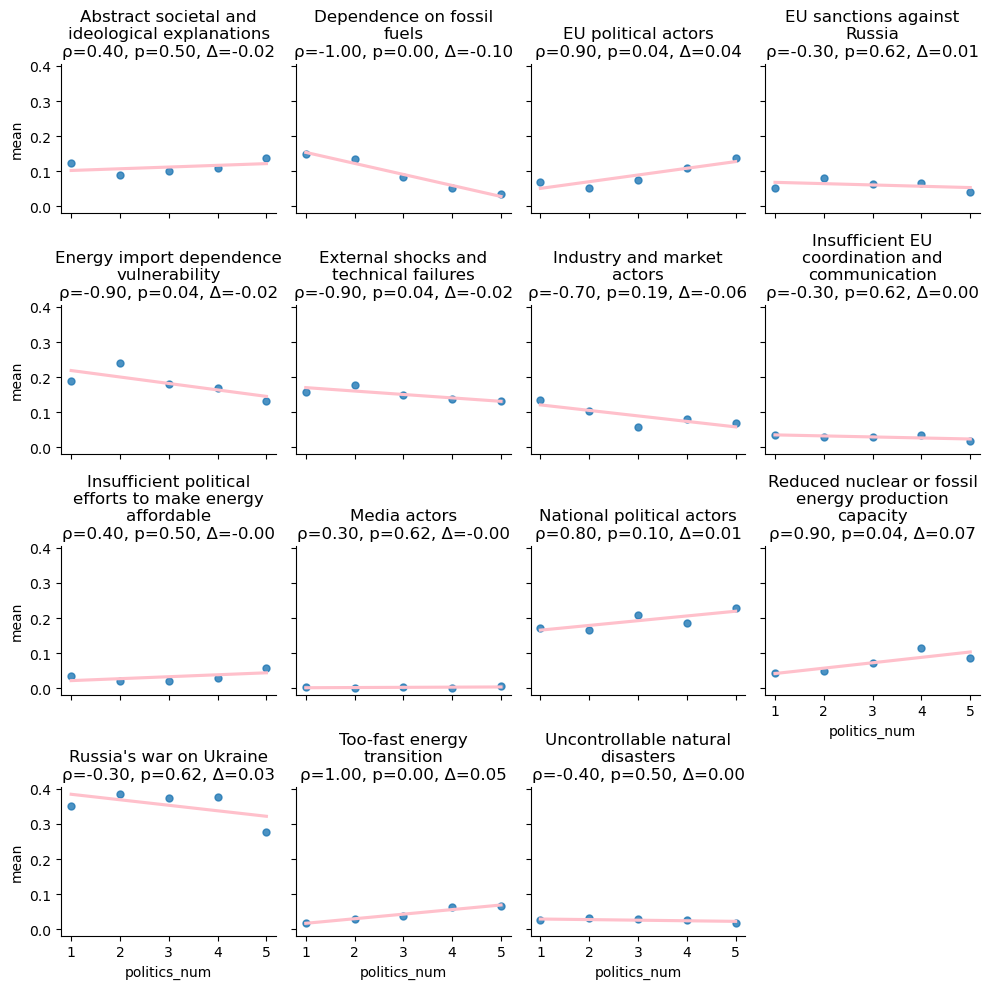

In [26]:
from scipy.stats import spearmanr

df_cpi = x_mode.join(df[["country",'politics_num','income_num']])


d = (df_cpi.groupby('politics_num')[x_mode.columns].mean()
     .reset_index()
     .assign(politics_num=lambda x: pd.to_numeric(x['politics_num'], errors='coerce'))
     .dropna(subset=['politics_num'])
     .melt('politics_num', var_name='item', value_name='mean'))

def wrap_label(x, width=25):
    return "\n".join(textwrap.wrap(str(x), width=width, break_long_words=False))


title_map = {
    item: (
        f"{wrap_label(item)}\n"
        f"ρ={res.statistic:.2f}, p={res.pvalue:.2f}, Δ={delta:.2f}"
    )
    for item, g in d.groupby('item')
    for g2 in [g.sort_values("politics_num")]
    for res in [spearmanr(g2["politics_num"], g2["mean"])]
    for delta in [g2["mean"].iloc[-2:-1].mean() - g2["mean"].iloc[0:1].mean()]
}
g = sns.lmplot(
    data=d, x='politics_num', y='mean',
    col='item', col_wrap=4,
    height=2.5,aspect=1,
    order=1, ci=None,
    scatter_kws={'s': 25},
    line_kws={'color': 'pink'}
)


# Adjust the distance between subplots
plt.subplots_adjust(wspace=0.3, hspace=0.4)

for ax, item in zip(g.axes.flat, g.col_names):
    ax.set_title(title_map[item])

plt.tight_layout()
plt.savefig(f"{date_str} FaceGrid causes political orientation.pdf")

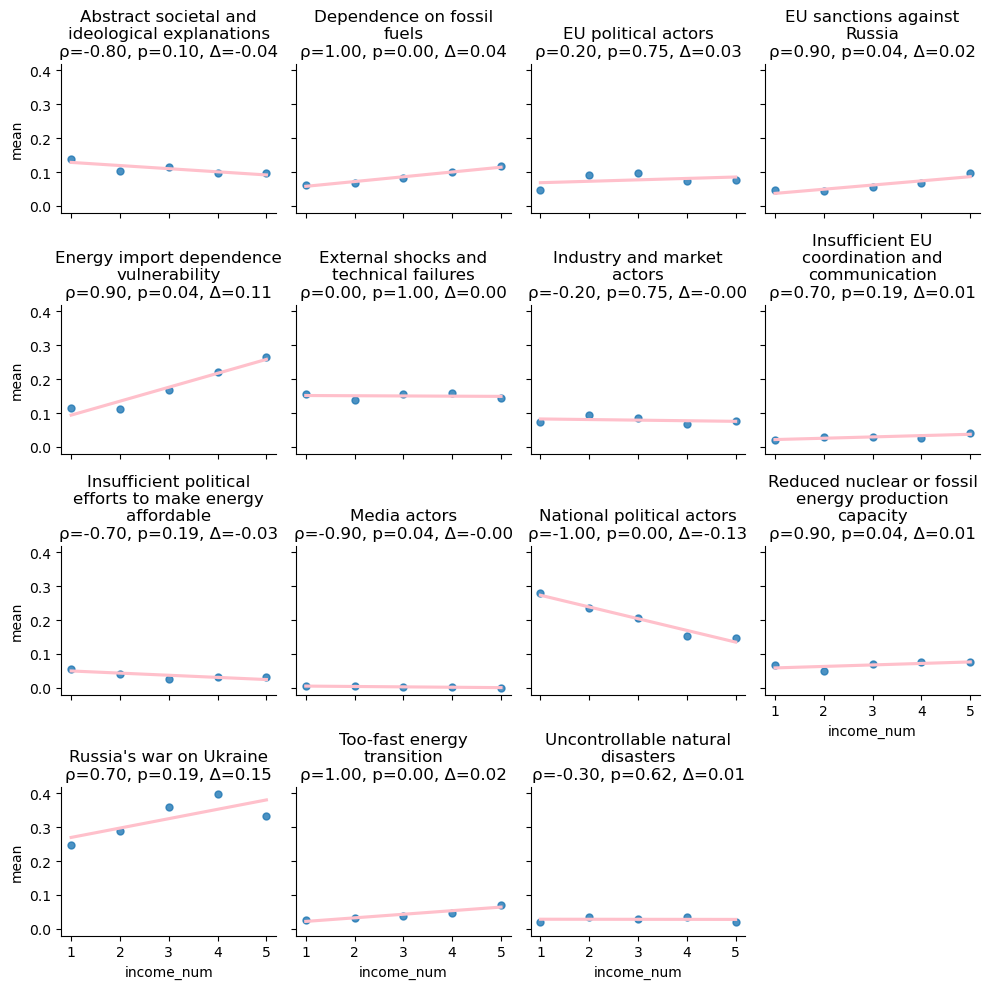

In [28]:
from scipy.stats import spearmanr


items = list(x_mode.columns)

# plot data: group means
d = (df_cpi.groupby('income_num')[items].mean()
     .reset_index()
     .assign(income_num=lambda x: pd.to_numeric(x['income_num'], errors='coerce'))
     .dropna(subset=['income_num'])
     .melt('income_num', var_name='item', value_name='mean'))


def wrap_label(x, width=25):
    return "\n".join(textwrap.wrap(str(x), width=width, break_long_words=False))

title_map = {
    item: (
        f"{wrap_label(item)}\n"
        f"ρ={res.statistic:.2f}, p={res.pvalue:.2f}, Δ={delta:.2f}"
    )
    for item, g in d.groupby('item')
    for g2 in [g.sort_values("income_num")]
    for res in [spearmanr(g2["income_num"], g2["mean"])]
    for delta in [(g2["mean"].iloc[-2:-1].mean() - g2["mean"].iloc[:1].mean())]
}
        
# plot
g = sns.lmplot(
    data=d, x='income_num', y='mean',
    col='item', col_wrap=4,
    height=2.5,
    order=1, ci=None,
    scatter_kws={'s': 25},
    line_kws={'color': 'pink'}
)


# Adjust the distance between subplots
plt.subplots_adjust(wspace=0.3, hspace=0.4)

for ax, item in zip(g.axes.flat, g.col_names):
    ax.set_title(title_map[item])
plt.tight_layout()
plt.savefig(f"{date_str} FaceGrid causes income.pdf")

# Topic modeling

In [30]:
import pandas as pd
import MaxStat

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic

def Topic_modeling(sub, text_col="QID8", nr_repr_docs=10):
    df = sub[[text_col]].dropna().copy()
    df["doc_id"] = df.index
    df = df.rename(columns={text_col: "Document"})

    docs = df["Document"].tolist()
    doc_ids = df["doc_id"].tolist()

    embedder = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
    embeddings = embedder.encode(docs, show_progress_bar=True)

    topic_model = BERTopic(
        language="multilingual",
        embedding_model=embedder,
        nr_topics=5,
        min_topic_size=50
    )

    topics, _ = topic_model.fit_transform(docs, embeddings)
    df["Topic"] = topics

    documents = df[["Document", "Topic", "doc_id"]].copy()


    ## Needed to get 10 topics
    repr_docs, _, _, _ = topic_model._extract_representative_docs(
        c_tf_idf=topic_model.c_tf_idf_,
        documents=documents,
        topics=topic_model.topic_representations_,
        nr_repr_docs=nr_repr_docs
    )


    repr_docs_ids = {}
    for t, reps in repr_docs.items():
        mask = documents["Document"].isin(reps) & documents["Topic"].eq(t)
        repr_docs_ids[t] = documents.loc[mask, "doc_id"].tolist()

    return topic_model, topics, repr_docs, repr_docs_ids, documents

def topic_statistics(df: pd.DataFrame, topic_model,country_tresh=0.1):
    
    topics = pd.Series(topic_model.topics_, index=df.index, dtype="Int64")
    df["Topic"]=topics
    
    inc = MaxStat.mwu_group_vs_rest(df, "Topic", "income_num", ("Higher", "Lower"))
    pol = MaxStat.mwu_group_vs_rest(df, "Topic", "politics_num", ("More right", "More left"))

    
    dummies = pd.get_dummies(df["Topic"])

    df_ct = pd.concat([df["country"], dummies], axis=1)

   # ctr = MaxStat.topic_country_association(df_ct, topic_col=new_columns.columns, country_col="country", n_resamples=1.96, alpha=0.05)

   # print(df_ct,dummies)
    ctr = MaxStat.topic_country_association(
        df          = df_ct ,
        country_col = "country",
        topic_col  = [t for t in list(dummies.columns) if t>=0],   # list of dummy column names
        phi_thr   = country_tresh,
        alpha       = 0.05                # keep default Monte‑Carlo resamples (20 000)
    )

        
    return inc, pol, ctr


def create_LLM_labels(topic_model,prompt):
    summaries={}


    # create client for summary of clusters
    
    from openai import OpenAI
    
    client = MaxNLP.create_client()
    
    for topic in topic_model.representative_docs_.keys():
        if topic == -1:
            continue
    
        response = client.chat.completions.create(
            model='FAST.gpt-oss:120b',
            messages=[{
                "role": "user",
                "content": prompt + "\n\n" + "\n".join(topic_model.representative_docs_[topic][:20])
            }]
        ).choices[0].message.content

        summaries[topic] = response
    return summaries
    

def create_df_topics(repr_docs, repr_docs_ids, summaries, country_out, income_out, politics_out):
    size=pd.Series(topic_model.topics_, dtype="Int64").value_counts()
    rows = []
    for topic, docs_list in repr_docs.items():
        if topic == -1:
            continue
        #print(topic)
        label, rest = summaries[topic].split(":", 1)
        short_label = label.replace("*", "").strip().title()
        narrative   = rest[0].replace("*", "").strip() if rest else ""
        rows.append(
            {
                "themectr = MaxStat.": short_label,
                "narrative": narrative,
                "size":size[topic],
                "representative_doc_ids": repr_docs_ids.get(topic, []),
                "country_over  [φ]": country_out.loc[topic, "over_countries [φ]"],
                "country_under  [φ]":country_out.loc[topic, "under_countries [φ]"],
                #"country_associations": country_out.loc[topic, ["over_countries [φ]","under_countries [φ]"]], ### THIS DOES NOT WORK YET! the code summary is not produced
                "income_association [r, MWU]": income_out.get(topic, ""),
                "political_orientation_association [r, MWU]": politics_out.get(topic, ""),
            }
        )
    return pd.DataFrame(rows)

Batches:   0%|          | 0/27 [00:00<?, ?it/s]

Nebula client loaded


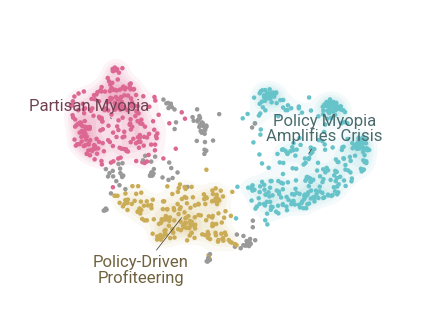

In [33]:
text_column="QID8"
focus_col='National political actors'

columns=[text_column,"country","income_num","politics_num"]

df_cpit=x_mode.join(df[columns])

sub = df_cpit[df_cpit[focus_col]==1]

prompt=f"""These text represent perceived {codebook_name} of the EU energy crisis in a survey, further explaining the cause: {focus_col}.They have been further clustered and you get 20 representative documents from one cluster of {focus_col}. Ground your summary only on these documents and focus on what makes this cluster special.
Summarize these texts as a qualitative research theme/narrative in accesible publishable language (in 30 words). The Label emphasizes a particularity of {focus_col}.
Response structure: *LABEL* (1-5 words) :  *NARRATIVE* (50 words)"""


sub[["income_num","politics_num"]] = sub[["income_num","politics_num"]].apply(pd.to_numeric, errors='coerce')

## Call the functions to create the topic model, statistics, and llm summaries

topic_model, topics, repr_docs, repr_docs_ids,documents=Topic_modeling(sub,text_col="QID8")
income_out, politics_out, country_out=topic_statistics(sub,  topic_model,country_tresh=.1)
summaries=create_LLM_labels(topic_model,prompt)
df_topics = create_df_topics(repr_docs,repr_docs_ids,summaries,country_out,income_out,politics_out)

MaxStat.vizualize_topics(topic_model,sub,summaries,label_font_size=12,figsize=(4.5, 3.5),filename=f"topics_publication_{focus_col} shocks.pdf")
df_topics
plt.show()
